## Menna Ali Mohamed  20230371
## Arwa Sameh 20230039
## Rawan Hany 20230106

## Introduction

Diabetes is one of the most common chronic diseases that affects millions of people worldwide. Early prediction and diagnosis of diabetes using machine learning techniques can help improve healthcare decisions and reduce health risks.

In this project, a complete machine learning workflow was implemented using the Diabetes dataset. The project started with data loading, preprocessing, and exploratory data analysis (EDA) to understand the relationships between features and detect patterns within the dataset. Different visualization techniques such as heatmaps, count plots, distribution plots, and box plots were used to analyze the data effectively.

Several machine learning classification models were then trained and evaluated, including Logistic Regression, Support Vector Classifier (SVC), Random Forest Classifier, and Gradient Boosting Classifier. The models were compared using evaluation metrics such as Accuracy, Recall, Precision, F1-Score, and Confusion Matrix to determine the best-performing model.

In addition, MLflow was integrated into the project for experiment tracking, parameter logging, metric recording, and model management. This helped organize experiments, compare model performances, and safely save trained models for future use and reproducibility.

---

**Importing Libraries & Preparing the Machine Learning Environment**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score,recall_score,f1_score
from sklearn.metrics import classification_report

plt.style.use('fivethirtyeight')
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import mlflow
import mlflow.sklearn
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score


**Loading and Exploring the Dataset**


In [2]:
df=pd.read_csv('diabetes.csv')

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [6]:
print(df.duplicated().sum())

0


**Correlation Matrix Analysis**

**Function:**
Used to calculate the correlation between numerical features in the dataset to identify relationships and dependencies between variables.

In [7]:
df.corr()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.129459,0.141282,-0.081672,-0.073535,0.017683,-0.033523,0.544341,0.221898
Glucose,0.129459,1.000000,0.152590,0.057328,0.331357,0.221071,0.137337,0.263514,0.466581
BloodPressure,0.141282,0.152590,1.000000,0.207371,0.088933,0.281805,0.041265,0.239528,0.065068
SkinThickness,-0.081672,0.057328,0.207371,1.000000,0.436783,0.392573,0.183928,-0.113970,0.074752
Insulin,-0.073535,0.331357,0.088933,0.436783,1.000000,0.197859,0.185071,-0.042163,0.130548
BMI,0.017683,0.221071,0.281805,0.392573,0.197859,1.000000,0.140647,0.036242,0.292695
DiabetesPedigreeFunction,-0.033523,0.137337,0.041265,0.183928,0.185071,0.140647,1.000000,0.033561,0.173844
Age,0.544341,0.263514,0.239528,-0.113970,-0.042163,0.036242,0.033561,1.000000,0.238356
Outcome,0.221898,0.466581,0.065068,0.074752,0.130548,0.292695,0.173844,0.238356,1.000000


**Heatmap Visualization**


Used to visualize the correlation matrix with color mapping and numerical values to easily understand relationships between dataset features.


<Axes: >

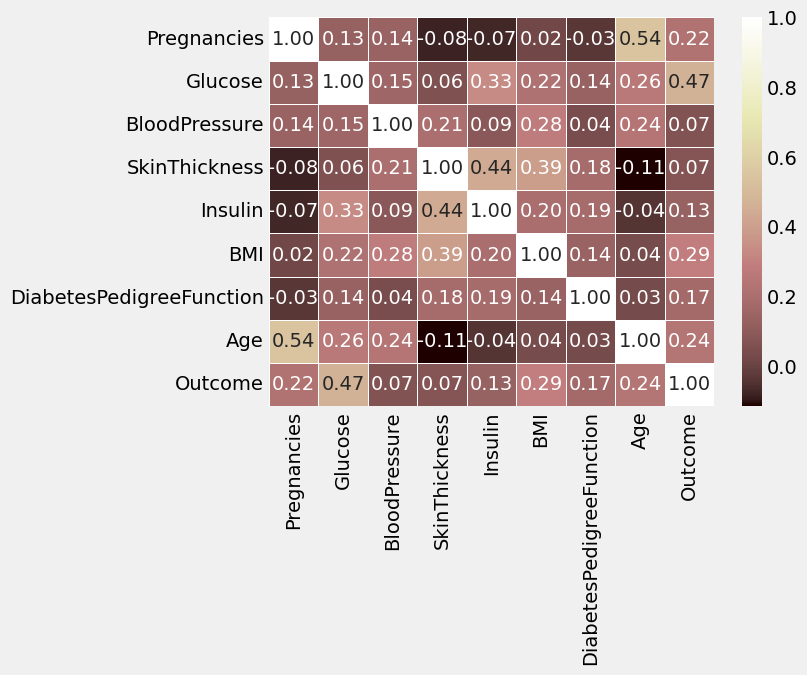

In [8]:
sns.heatmap(
    df.corr(),
    annot=True,
    fmt='0.2f',
    linewidth=.5,
    cmap='pink'
)

<Axes: xlabel='Outcome', ylabel='count'>

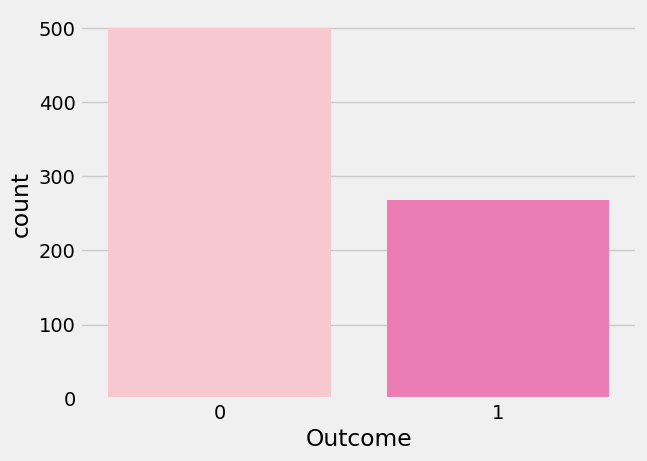

In [9]:
sns.countplot(
    x="Outcome",
    data=df,
    palette=['pink', 'hotpink']
)

**Pregnancies Feature Analysis and Visualization**

**Function:**
Used to analyze the `Pregnancies` feature through different visualizations including count plot, distribution plot, and box plot to understand data distribution, frequency, and detect outliers.


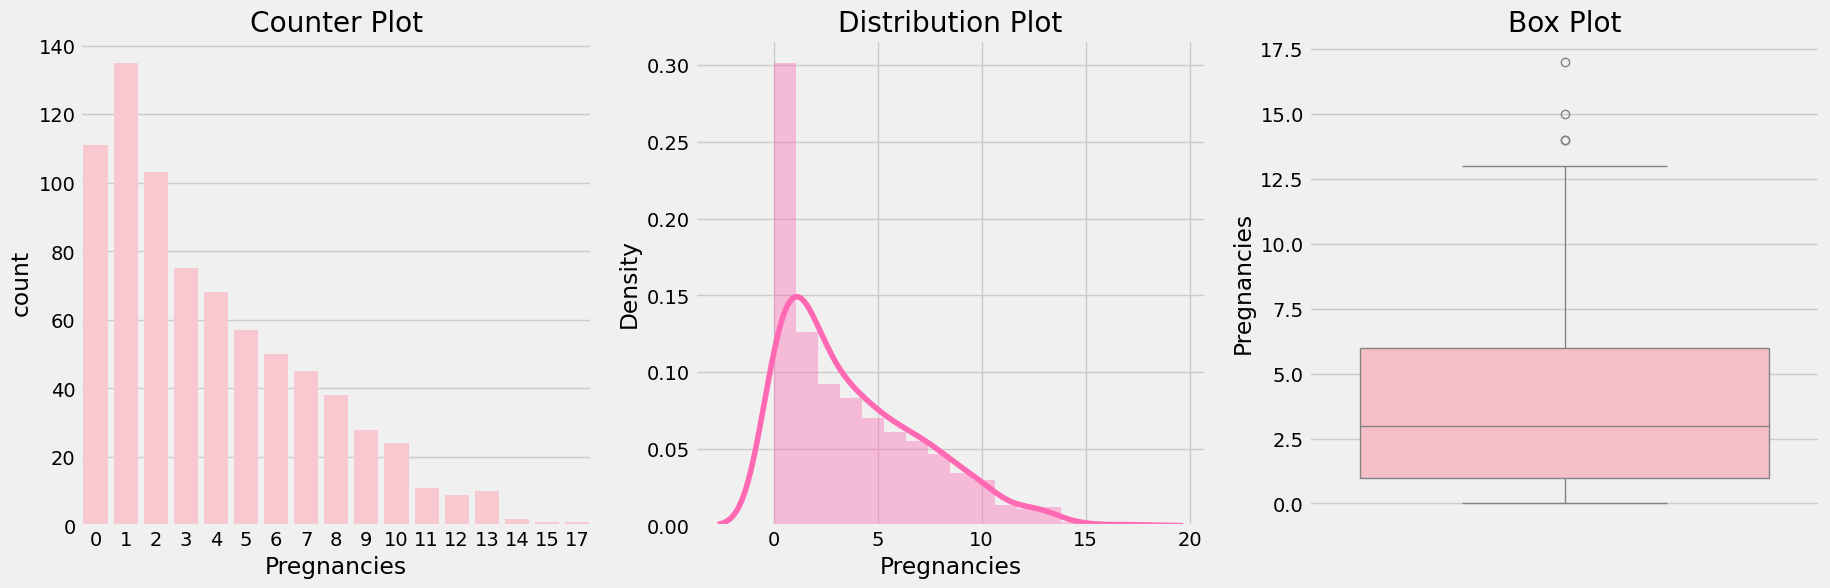

In [10]:
plt.figure(figsize=(20,6))

plt.subplot(1,3,1)
plt.title('Counter Plot')
sns.countplot(x='Pregnancies', data=df, color='pink')

plt.subplot(1,3,2)
plt.title('Distribution Plot')
sns.distplot(df['Pregnancies'], color='hotpink')

plt.subplot(1,3,3)
plt.title('Box Plot')
sns.boxplot(y=df['Pregnancies'], color='lightpink')

plt.show()

**Age Feature Box Plot Visualization**

**Function:**
Used to visualize the distribution of the `Age` feature and detect outliers using a box plot.


<Axes: xlabel='Age'>

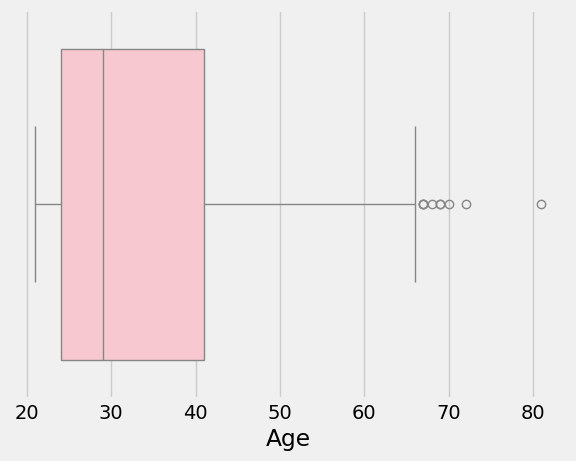

In [11]:
sns.boxplot(x=df.Age, color='pink')

## Create Model 

**Building, Training, and Evaluating Machine Learning Models**

**Function:**
Used to split the dataset into training and testing sets, train multiple machine learning classification models, evaluate their performance using Accuracy, Recall, and F1-Score metrics, visualize confusion matrices, compare model results in a dataframe, and display performance comparison graphs.


In [12]:
x=df.drop('Outcome',axis=1)
y=df['Outcome']

In [13]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2)

In [14]:
model1=LogisticRegression()
model2=SVC()
model3=RandomForestClassifier()
model4=GradientBoostingClassifier(n_estimators=1000)

In [15]:
columns=['LogisticRegression','SVC','RandomForestClassifier','GradientBoostingClassifier']
result1=[]
result2=[]
result3=[]

In [16]:
def cal(model):
    model.fit(x_train,y_train)
    pre=model.predict(x_test)
    accuracy=accuracy_score(pre,y_test)
    recall=recall_score(pre,y_test)
    f1=f1_score(pre,y_test)
    result1.append(accuracy)
    result2.append(recall)
    result3.append(f1)
    sns.heatmap(confusion_matrix(pre,y_test),annot=True)
    print(model)
    print("The Accuracy is",accuracy,"The Recall is:",recall ,"The F1 is :",f1)


**1 . Model 1 (LogisticRegression)**

LogisticRegression()
The Accuracy is 0.8246753246753247 The Recall is: 0.7777777777777778 The F1 is : 0.6746987951807228


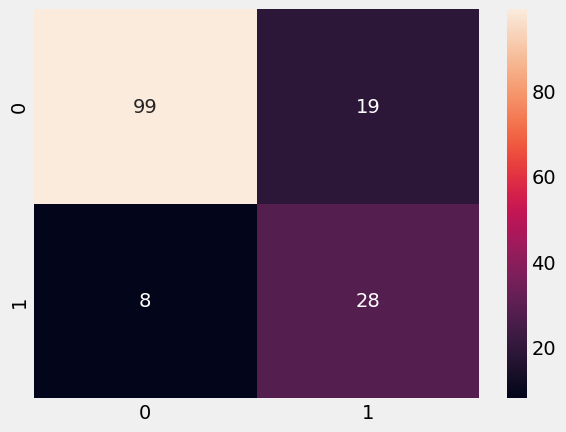

In [17]:
cal(model1)

**2 . Model 2 (SVC)**

SVC()
The Accuracy is 0.8311688311688312 The Recall is: 0.8888888888888888 The F1 is : 0.6486486486486487


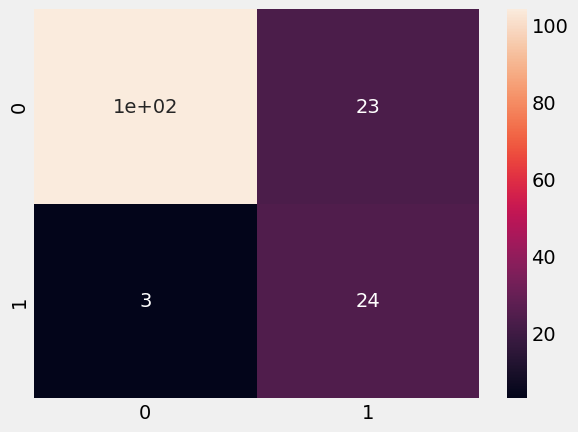

In [18]:
cal(model2)

**3 . Model 3 (RandomForestClassifier)**

RandomForestClassifier()
The Accuracy is 0.8376623376623377 The Recall is: 0.7619047619047619 The F1 is : 0.7191011235955056


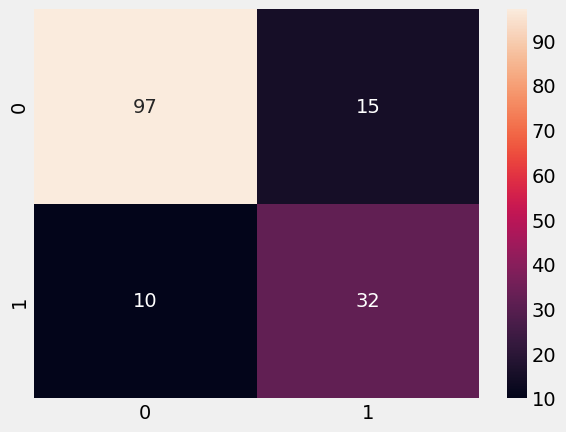

In [19]:
cal(model3)

**4 . Model 4 (GradientBoostingClassifier)**

GradientBoostingClassifier(n_estimators=1000)
The Accuracy is 0.8051948051948052 The Recall is: 0.6976744186046512 The F1 is : 0.6666666666666666


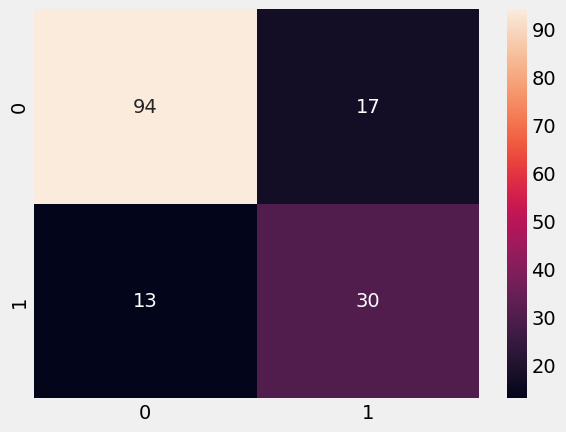

In [20]:
cal(model4)

In [21]:
Final_Result=pd.DataFrame({'Algorithm':columns,
                           'Accuracies':result1,
                           'Recall':result2 ,
                           'F1 Score':result3})
Final_Result

,Algorithm,Accuracies,Recall,F1 Score
0,LogisticRegression,0.824675,0.777778,0.674699
1,SVC,0.831169,0.888889,0.648649
2,RandomForestClassifier,0.837662,0.761905,0.719101
3,GradientBoostingClassifier,0.805195,0.697674,0.666667


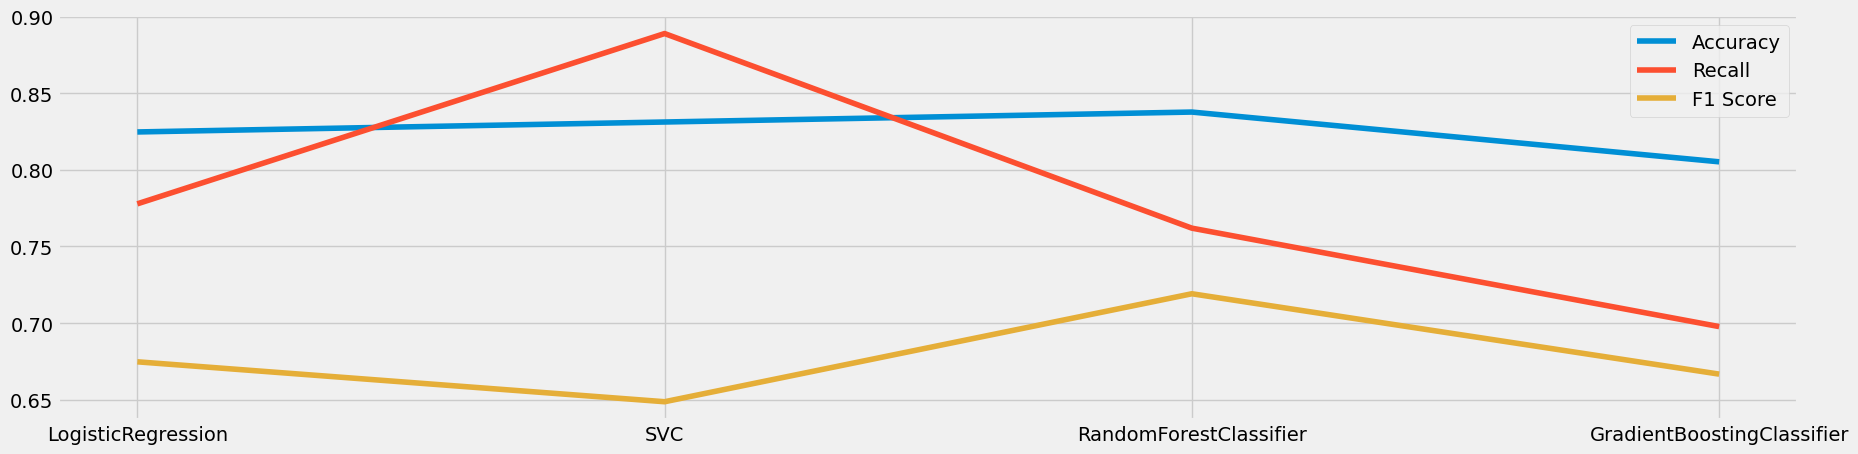

In [22]:
fig,ax=plt.subplots(figsize=(20,5))
plt.plot(Final_Result.Algorithm,result1,label="Accuracy")
plt.plot(Final_Result.Algorithm,result2,label="Recall")
plt.plot(Final_Result.Algorithm,result3,label="F1 Score")
plt.legend()
plt.show()

**create model From Sratch**

SVM from Scratch 

In [23]:
class SimpleSVM:
    def __init__(self, learning_rate=0.001, C=1.0, n_iters=1000):
        self.lr = learning_rate
        self.C = C
        self.n_iters = n_iters
        self.w = None
        self.b = None
    
    def fit(self, X, y):
        n_samples, n_features = X.shape
        y_ = np.where(y == 0, -1, 1)
        
        self.w = np.zeros(n_features)
        self.b = 0
        
        for _ in range(self.n_iters):
            for idx, x_i in enumerate(X):
                condition = y_[idx] * (np.dot(x_i, self.w) + self.b) >= 1
                if condition:
                    dw = 2 * (1/self.C) * self.w
                    db = 0
                else:
                    dw = 2 * (1/self.C) * self.w - np.dot(x_i, y_[idx])
                    db = -y_[idx]
                
                self.w -= self.lr * dw
                self.b -= self.lr * db
    
    def predict(self, X):
        decision = np.dot(X, self.w) + self.b
        return np.where(decision >= 0, 1, 0)

**Load and Prepare Data**

In [24]:
print("SVM FROM SCRATCH")
X = df.drop('Outcome', axis=1).values
y = df['Outcome'].values

SVM FROM SCRATCH


**Split Data**

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"\nTraining samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")



Training samples: 614
Testing samples: 154


**Feature Scaling**

In [26]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

**Train SVM with Different Parameters**

**Hyperparameter Explanation for Model Optimization**

**Function:**
Used to explain important machine learning hyperparameters such as Learning Rate (`LR`) and Regularization Parameter (`C`) that help improve model training and performance.


In [27]:
print("\n" + "="*50)
print("TRAINING SVM WITH DIFFERENT PARAMETERS")
print("="*50)

best_accuracy = 0
best_params = {}
best_model = None
results = []

for lr in [0.001, 0.005, 0.01, 0.05]:
    for c in [0.1, 1.0, 5.0, 10.0]:
        svm = SimpleSVM(learning_rate=lr, C=c, n_iters=500)
        svm.fit(X_train, y_train)
        y_pred = svm.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        
        results.append({'LR': lr, 'C': c, 'Accuracy': acc})
        
        if acc > best_accuracy:
            best_accuracy = acc
            best_params = {'LR': lr, 'C': c}
            best_model = svm
        
        print(f"LR={lr}, C={c} => Accuracy: {acc:.4f}")


TRAINING SVM WITH DIFFERENT PARAMETERS
LR=0.001, C=0.1 => Accuracy: 0.6429
LR=0.001, C=1.0 => Accuracy: 0.6429
LR=0.001, C=5.0 => Accuracy: 0.7792
LR=0.001, C=10.0 => Accuracy: 0.8052
LR=0.005, C=0.1 => Accuracy: 0.6429
LR=0.005, C=1.0 => Accuracy: 0.6429
LR=0.005, C=5.0 => Accuracy: 0.7922
LR=0.005, C=10.0 => Accuracy: 0.8117
LR=0.01, C=0.1 => Accuracy: 0.6429
LR=0.01, C=1.0 => Accuracy: 0.6429
LR=0.01, C=5.0 => Accuracy: 0.7792
LR=0.01, C=10.0 => Accuracy: 0.7987
LR=0.05, C=0.1 => Accuracy: 0.6429
LR=0.05, C=1.0 => Accuracy: 0.6494
LR=0.05, C=5.0 => Accuracy: 0.7792
LR=0.05, C=10.0 => Accuracy: 0.8182


**Displaying Best Model Hyperparameters**

**Function:**
Used to display the best optimized hyperparameter values for the machine learning model, including Learning Rate, Regularization Parameter (`C`), and the number of training iterations.


In [28]:
print("\n" + "="*50)
print("BEST MODEL RESULTS")
print("="*50)

print(f"\nBest Parameters:")
print(f"  Learning Rate: {best_params['LR']}")
print(f"  C (Regularization): {best_params['C']}")
print(f"  Iterations: 500")


BEST MODEL RESULTS

Best Parameters:
  Learning Rate: 0.05
  C (Regularization): 10.0
  Iterations: 500


**Best Model Prediction and Performance Evaluation**

**Function:**
Used to generate predictions using the best trained model and evaluate its performance through Accuracy, Precision, Recall, F1-Score, and Confusion Matrix metrics.


In [29]:
y_pred_best = best_model.predict(X_test)

print(f"\n{'='*40}")
print(f"ACCURACY: {best_accuracy:.4f} = {best_accuracy*100:.2f}%")
print(f"{'='*40}")

print(f"\nPrecision: {precision_score(y_test, y_pred_best):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_best):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_best):.4f}")

print(f"\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))



ACCURACY: 0.8182 = 81.82%

Precision: 0.7647
Recall:    0.7091
F1-Score:  0.7358

Confusion Matrix:
[[87 12]
 [16 39]]


# --> MLFlow

**1. Splitting Dataset into Training and Testing Sets**

**Function:**
Used to divide the dataset into training and testing data to train machine learning models and evaluate their performance on unseen data.


In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

**2 .Defining Machine Learning Models**

**Function:**
Used to create and configure multiple machine learning classification models with specific hyperparameters for training and performance comparison.


In [31]:
models = {
    "RandomForest": RandomForestClassifier(n_estimators=100, random_state=42),
    "GradientBoosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
    "LogisticRegression": LogisticRegression(max_iter=200, random_state=42)
}

**3. Training, Evaluating, and Tracking Models with MLflow**

**Function:**
Used to train multiple machine learning models, evaluate their accuracy, log hyperparameters and performance metrics into MLflow, and save the trained models for experiment tracking and model management.


In [32]:
import mlflow
import mlflow.sklearn
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [33]:
for model_name, model in models.items():
    mlflow.set_experiment(f"Diabetes_{model_name}")
    
    with mlflow.start_run(run_name=f"Diabetes_{model_name}_Run"):
        model.fit(X_train, y_train)
        
        y_pred = model.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred)
        
        if model_name == "RandomForest":
            mlflow.log_params({
                "n_estimators": 100,
                "random_state": 42
            })
            
        elif model_name == "GradientBoosting":
            mlflow.log_params({
                "n_estimators": 100,
                "learning_rate": 0.1,
                "random_state": 42
            })
            
        elif model_name == "LogisticRegression":
            mlflow.log_params({
                "max_iter": 200,
                "random_state": 42
            })
        
        mlflow.log_metric("accuracy", accuracy)
        
        mlflow.sklearn.log_model(
            sk_model=model,
            name=f"{model_name.lower()}_diabetes_model",
            serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_SKOPS
        )
        
        print(f"✅ {model_name} Accuracy on Diabetes: {accuracy:.3f} ({accuracy*100:.2f}%)")

✅ RandomForest Accuracy on Diabetes: 0.721 (72.08%)
✅ GradientBoosting Accuracy on Diabetes: 0.740 (74.03%)
✅ LogisticRegression Accuracy on Diabetes: 0.747 (74.68%)


**Training and Logging Gradient Boosting Model with MLflow**

**Function:**
Used to train a Gradient Boosting classification model, evaluate its accuracy, record hyperparameters and performance metrics in MLflow, and save the trained model for experiment tracking and reproducibility.


In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

mlflow.set_experiment("GradientBoosting_Diabetes")

with mlflow.start_run(run_name="GB_Diabetes_100"):
    model = GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    )
    
    model.fit(X_train, y_train)
    
    accuracy = accuracy_score(y_test, model.predict(X_test))
    
    mlflow.log_params({
        "n_estimators": 100,
        "learning_rate": 0.1
    })
    
    mlflow.log_metric("accuracy", accuracy)
    
    mlflow.sklearn.log_model(
        sk_model=model,
        name="gradient_boosting_diabetes_model",
        serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_SKOPS
    )
    
    print(f"✅ GradientBoosting Accuracy on Diabetes: {accuracy:.3f}")

✅ GradientBoosting Accuracy on Diabetes: 0.740


**Training and Safely Saving Random Forest Model with MLflow**

**Function:**
Used to train a Random Forest classification model, evaluate its accuracy, log parameters and metrics into MLflow, and safely save the trained model using the SKOPS serialization format for secure model storage and reproducibility.


In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

mlflow.set_experiment("Diabetes_Experiments_Skops")

with mlflow.start_run(run_name="RF_Diabetes_Safe"):
    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
    
    model.fit(X_train, y_train)
    
    accuracy = accuracy_score(y_test, model.predict(X_test))
    
    mlflow.log_param("n_estimators", 100)
    mlflow.log_metric("accuracy", accuracy)
    
    mlflow.sklearn.log_model(
        sk_model=model,
        name="diabetes_model",
        serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_SKOPS
    )
    
    print(f"✅ RandomForest Accuracy on Diabetes: {accuracy:.3f}")

✅ RandomForest Accuracy on Diabetes: 0.721


**Retrieving Experiment Runs from MLflow**

**Function:**
Used to connect to MLflow, access experiment runs, and display stored model metrics, parameters, and Run IDs for experiment tracking and comparison.


In [36]:
from mlflow.tracking import MlflowClient

client = MlflowClient()

experiment = client.get_experiment_by_name("Diabetes_RandomForest")
runs = client.search_runs(experiment.experiment_id)

for run in runs:
    print(f"Run ID: {run.info.run_id}")
    print(f"Metrics: {run.data.metrics}")
    print(f"Parameters: {run.data.params}")
    print("-" * 40)

Run ID: 6d436a9be261420f947f2614b54e28f0
Metrics: {'accuracy': 0.7207792207792207}
Parameters: {'n_estimators': '100', 'random_state': '42'}
----------------------------------------
Run ID: c790659aa5a04005a35b7748b5abdc4b
Metrics: {'accuracy': 0.7207792207792207}
Parameters: {'n_estimators': '100', 'random_state': '42'}
----------------------------------------


In [37]:
import joblib
import os

# Use 'model' because that is the name you used in your MLflow run
try:
    # Exporting the model to a standalone file
    joblib.dump(model, 'diabetes_model.pkl')
    
    print("✅ Success: Model saved as 'diabetes_model.pkl'")
    print(f"📂 Location: {os.getcwd()}")
    print("🚀 Your Streamlit app is now ready to use this model 'From Scratch'.")

except NameError:
    print("❌ Error: The variable 'model' is not defined.")
    print("👉 Please run the cell where you defined and fitted your RandomForestClassifier first.")
except Exception as e:
    print(f"❌ An unexpected error occurred: {e}")

✅ Success: Model saved as 'diabetes_model.pkl'
📂 Location: C:\Users\shop\Downloads\ML_Project
🚀 Your Streamlit app is now ready to use this model 'From Scratch'.


In [38]:
import mlflow
import os


mlflow.set_tracking_uri(f"file:///{os.getcwd()}/mlruns")


mlflow.set_experiment("Diabetes_Experiments_Skops")


with mlflow.start_run(run_name="Final_Model_Check"):
 
    model.fit(X_train, y_train)
  
    mlflow.sklearn.log_model(model, "model")
    print("✅ Experiment logged under 'Diabetes_Experiments_Skops'")

2026/05/14 09:32:07 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/14 09:32:07 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


✅ Experiment logged under 'Diabetes_Experiments_Skops'


---

## Project Summary

The project focused on building a machine learning system for diabetes prediction using classification algorithms. The workflow included:

* Importing and preparing the required Python libraries.
* Loading and exploring the dataset using pandas functions such as `head()`, `info()`, and `describe()`.
* Performing Exploratory Data Analysis (EDA) using correlation matrices and visualizations.
* Analyzing important features such as `Pregnancies`, `Age`, and `Outcome`.
* Splitting the dataset into training and testing sets.
* Training multiple machine learning models:

  * Logistic Regression
  * Support Vector Classifier (SVC)
  * Random Forest Classifier
  * Gradient Boosting Classifier
* Evaluating model performance using:

  * Accuracy
  * Precision
  * Recall
  * F1-Score
  * Confusion Matrix
* Comparing model results visually using graphs and tables.
* Using MLflow to:

  * Track experiments
  * Log hyperparameters and metrics
  * Save trained models securely
  * Retrieve experiment results and compare runs

The project demonstrated how machine learning and experiment tracking tools can be combined to build an organized, efficient, and reproducible diabetes prediction system.
